# BPM aligned threshold and performance bands

A separate experiment, started 25 October 2026. We ask how observed draft rates vary across peer environments for the **top 2%, next 8%, and next 20%** of season-standardized BPM. Theta and band membership now use the same final-season reference population. These are empirical outcomes, not simulated selection probabilities.

The original PPM and BPM notebooks and their saved results remain unchanged. This experiment changes both the threshold reference and the band definitions; it does not isolate the effect of one parameter. No significance tests or new minutes cutoff are included.

## 1 Settings and the connection between theta and the bands

At `theta_quantile = 0.98`, theta is the 98th percentile and the first band is automatically the top 2%. The next band runs from the top 10% up to that first band. The third runs from the top 30% up to the top 10%. There is no separate first-band setting to get out of sync.

Use **Run All after changing settings**, with `REBUILD_FIGURES = True`. Rebuilding files alone does not refresh old notebook outputs. Each display cell checks settings and prints the current run. Bands use rank-first ties; at a tied theta, top-band membership may include tied values. Actual above/equal counts are reported.

In [1]:
SETTINGS = {
    "theta_quantile": 0.98,
    "gamma": 6.0,
    "upper_band_end": 0.10,  # Cumulative top 10%; excludes the first band.
    "lower_band_end": 0.30,  # Cumulative top 30%; excludes the first two bands.
    "n_bins": 16,
    "thin_n": 30,
    "show_squid_jackal": True,
}
REBUILD_FIGURES = False  # Set True after changing any setting, then Run All.

## 2 Load or rebuild this experiment

Same 19,289 final-season candidates and outcome labels as the BPM baseline. Available BPM covers 2011–2021. BPM is standardized within season over full available eligible rosters. Theta and focal ranks then use these standardized values among final-season candidates. Shared and LOO roster pressure are calculated on full available team-season rosters before selecting bands.

Eligibility remains at least 20 recorded **season minutes**, not minutes per game, and more than 10 team games. Missing BPM is omitted, not treated as zero. Final season means the last observed eligible season in the saved window. K counts candidates who were ever drafted; K/N is not an annual draft quota.

In [2]:
from pathlib import Path
import json, importlib
import pandas as pd
from IPython.display import display, Image, Markdown
import aligned_bpm_analysis as analysis
importlib.reload(analysis)
RUN = analysis.run(SETTINGS) if REBUILD_FIGURES else analysis.load_latest(SETTINGS)
def show_run_settings():
    current = analysis.load_latest(SETTINGS)
    if current != RUN:
        raise ValueError("The latest run changed. Run All to refresh every output.")
    p = json.loads((RUN / "provenance.json").read_text())
    display(Markdown(f"**Run {RUN.name}** | BPM standardized within season | theta percentile {100*SETTINGS['theta_quantile']:g} | gamma {SETTINGS['gamma']:g} | bands top {100*p['top_fractions'][0]:g}%, then to top {100*p['top_fractions'][1]:g}%, then to top {100*p['top_fractions'][2]:g}%"))
    return p
p = show_run_settings()
print(f"Reference N={p['candidate_n']:,}, K={p['candidate_k']:,}, K/N={100*p['candidate_k']/p['candidate_n']:.2f}%")
print(f"theta={p['threshold']:.6f}; above theta={p['candidate_above_theta']:,}; equal theta={p['candidate_equal_theta']:,}")
print("Top band exactly equals candidates strictly above theta:", p['top_band_matches_strict_above_theta'])
display(pd.read_csv(RUN / 'cohort_summary.csv'))

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

Reference N=19,289, K=510, K/N=2.64%
theta=2.031487; above theta=386; equal theta=0
Top band exactly equals candidates strictly above theta: True


,cohort,label,observations,drafted,rate,above_theta,equal_theta,below_theta,colleges,team_seasons,under100_minutes,missing_teammates,min_performance,max_performance
0,top,Top 2% of BPM z,386,191,0.494819,386,0,0,150,325,75,68,2.033313,8.549079
1,middle,Top 10% excluding top 2%,1543,250,0.162022,0,0,1543,266,1023,101,282,1.284989,2.030910
2,lower,Top 30% excluding top 10%,3858,65,0.016848,0,0,3858,355,2151,246,726,0.518697,1.284989


## 3 The quantile mosaic

Rows are the three non-overlapping own-performance bands. Columns are LOO mean performance, shared roster pressure, and LOO roster pressure. Quantiles are calculated separately within each band and environmental axis: bin 16 is not an identical numerical environment across panels. Rank-first binning can split tied values. Y scales match within a row but may differ between rows. Broad bands do not hold own performance exactly fixed.

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

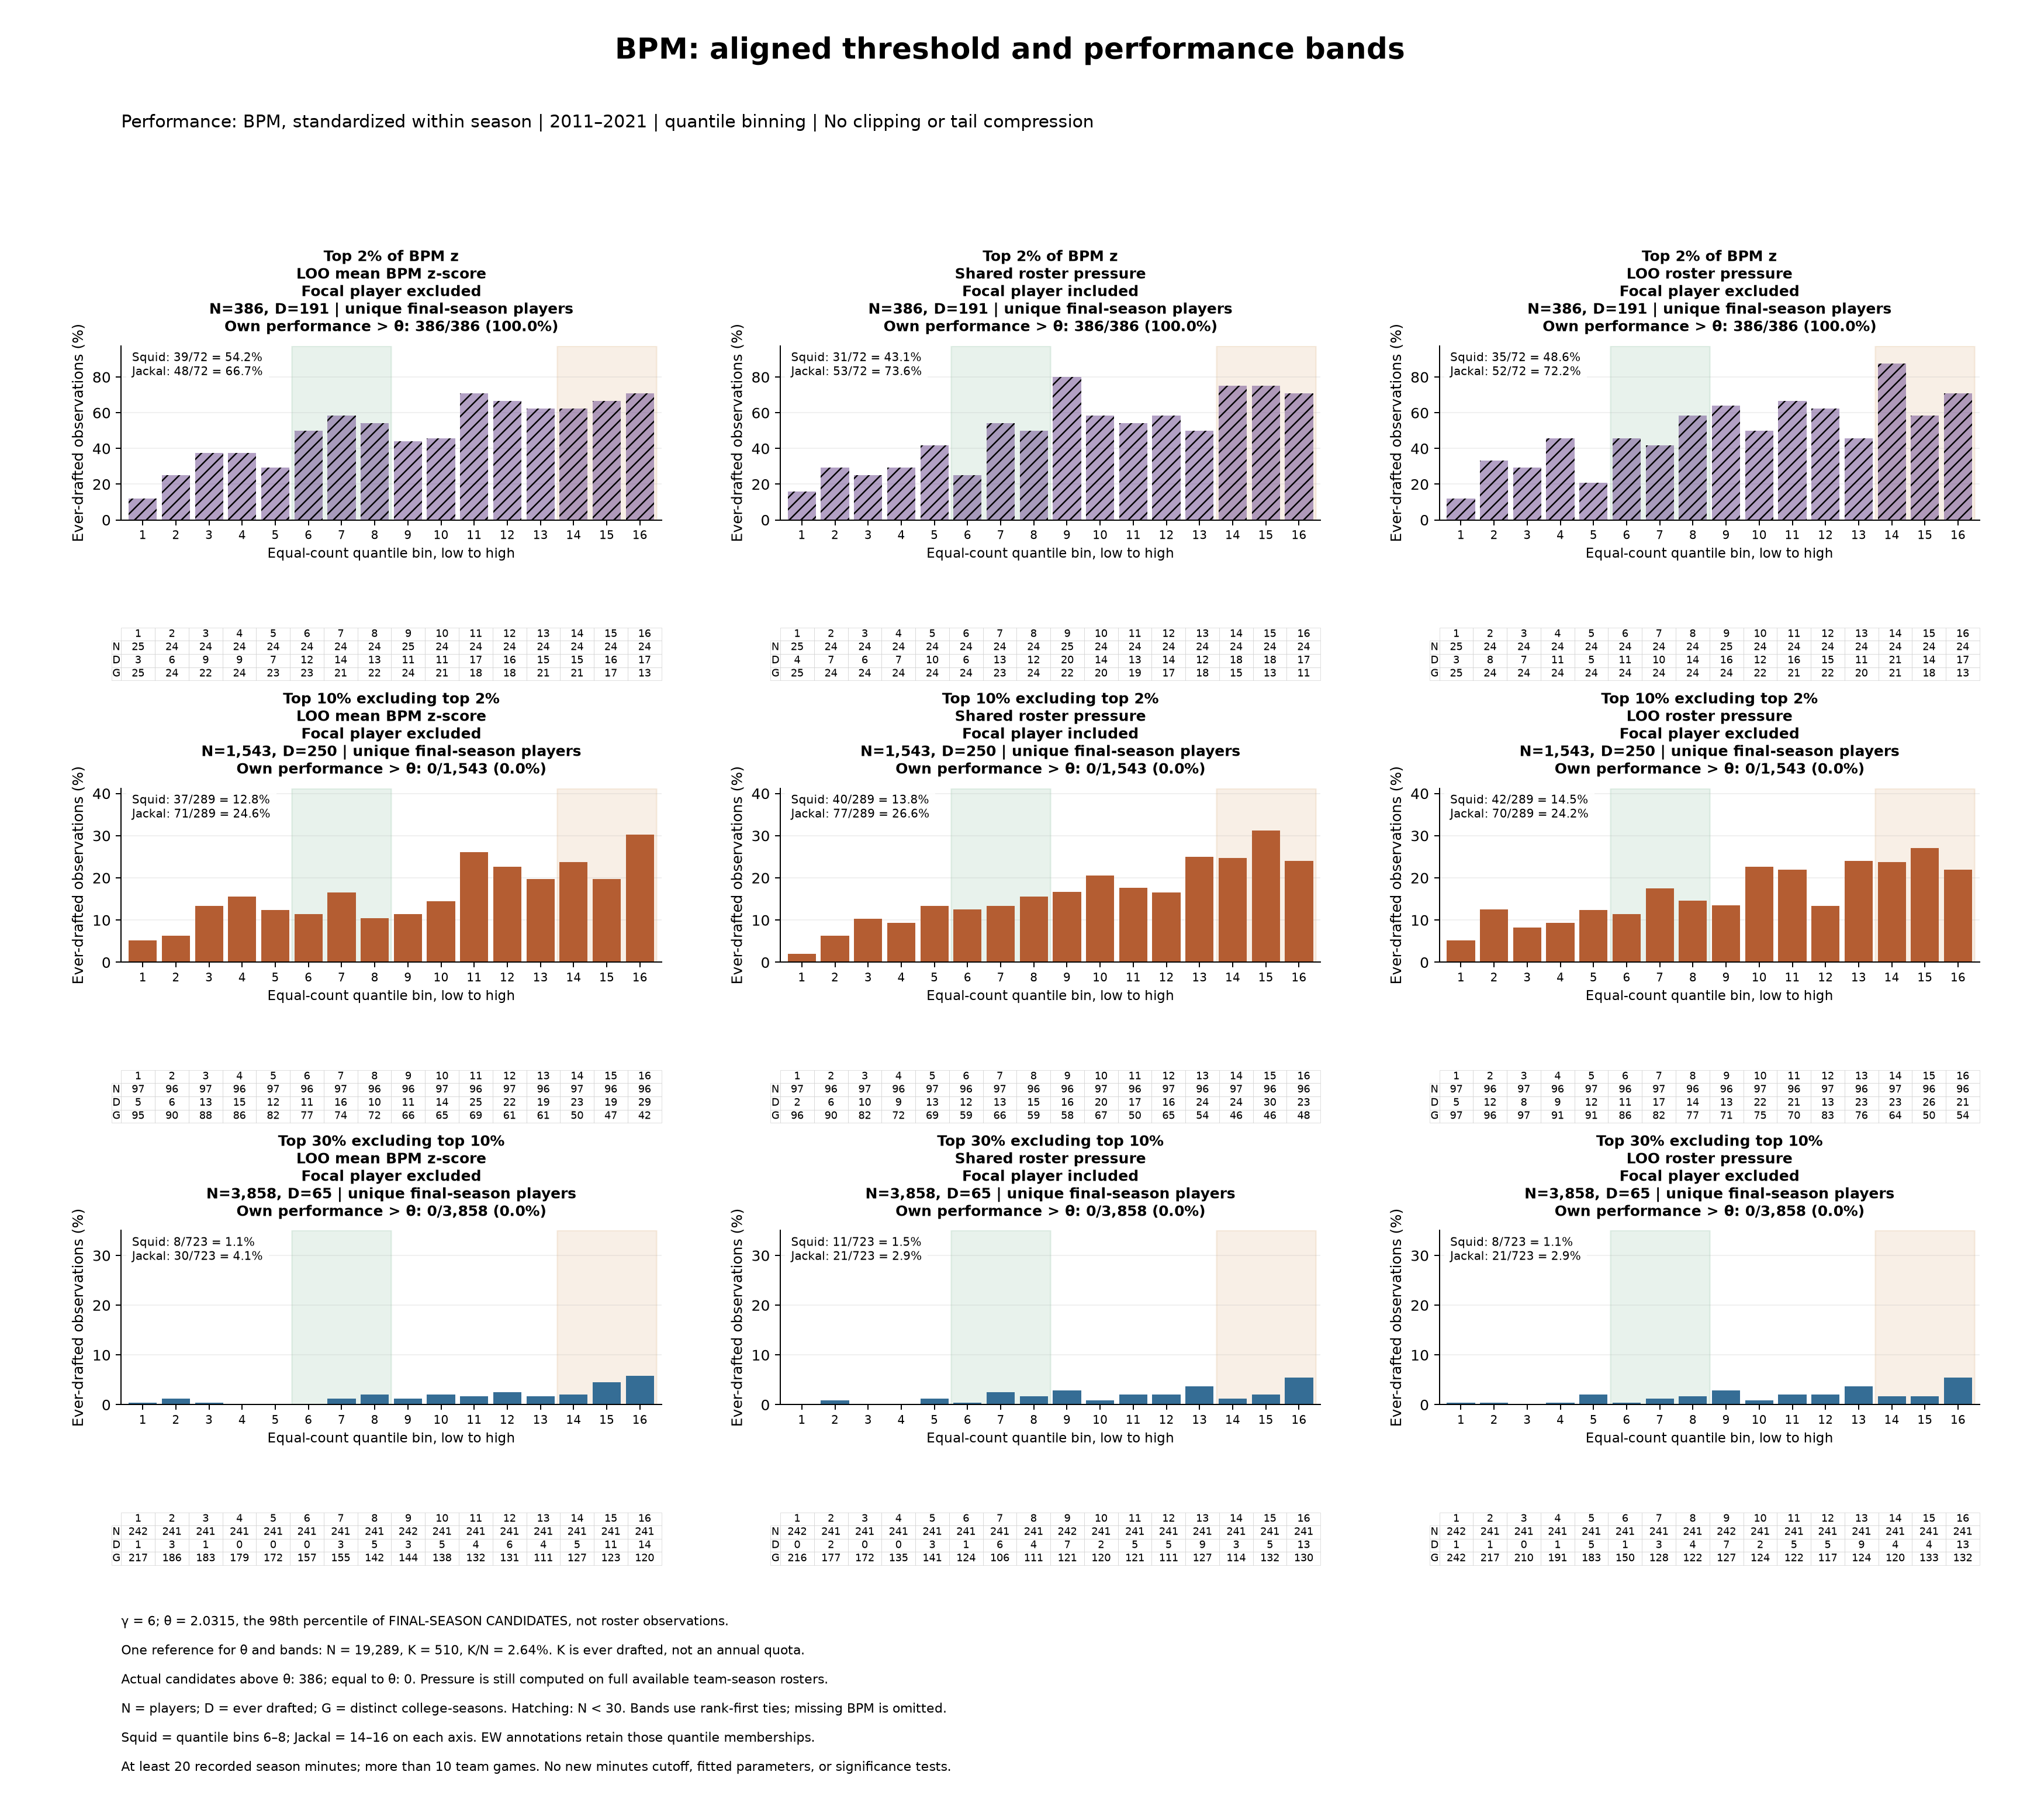

In [3]:
show_run_settings()
display(Image(filename=str(RUN / 'aligned_BPM_mosaic_quantile.png')))

## 4 Old-school HERO bars one band at a time

The same players appear on both axes of each pair. Removing the focal player from pressure can change environmental ranking and bin membership. N is players, D is ever drafted, G is distinct college-seasons. Hatching marks fewer than 30 observations, not a significance judgment. Squid and Jackal denote quantile bins 6–8 and 14–16, respectively.

### Top band

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

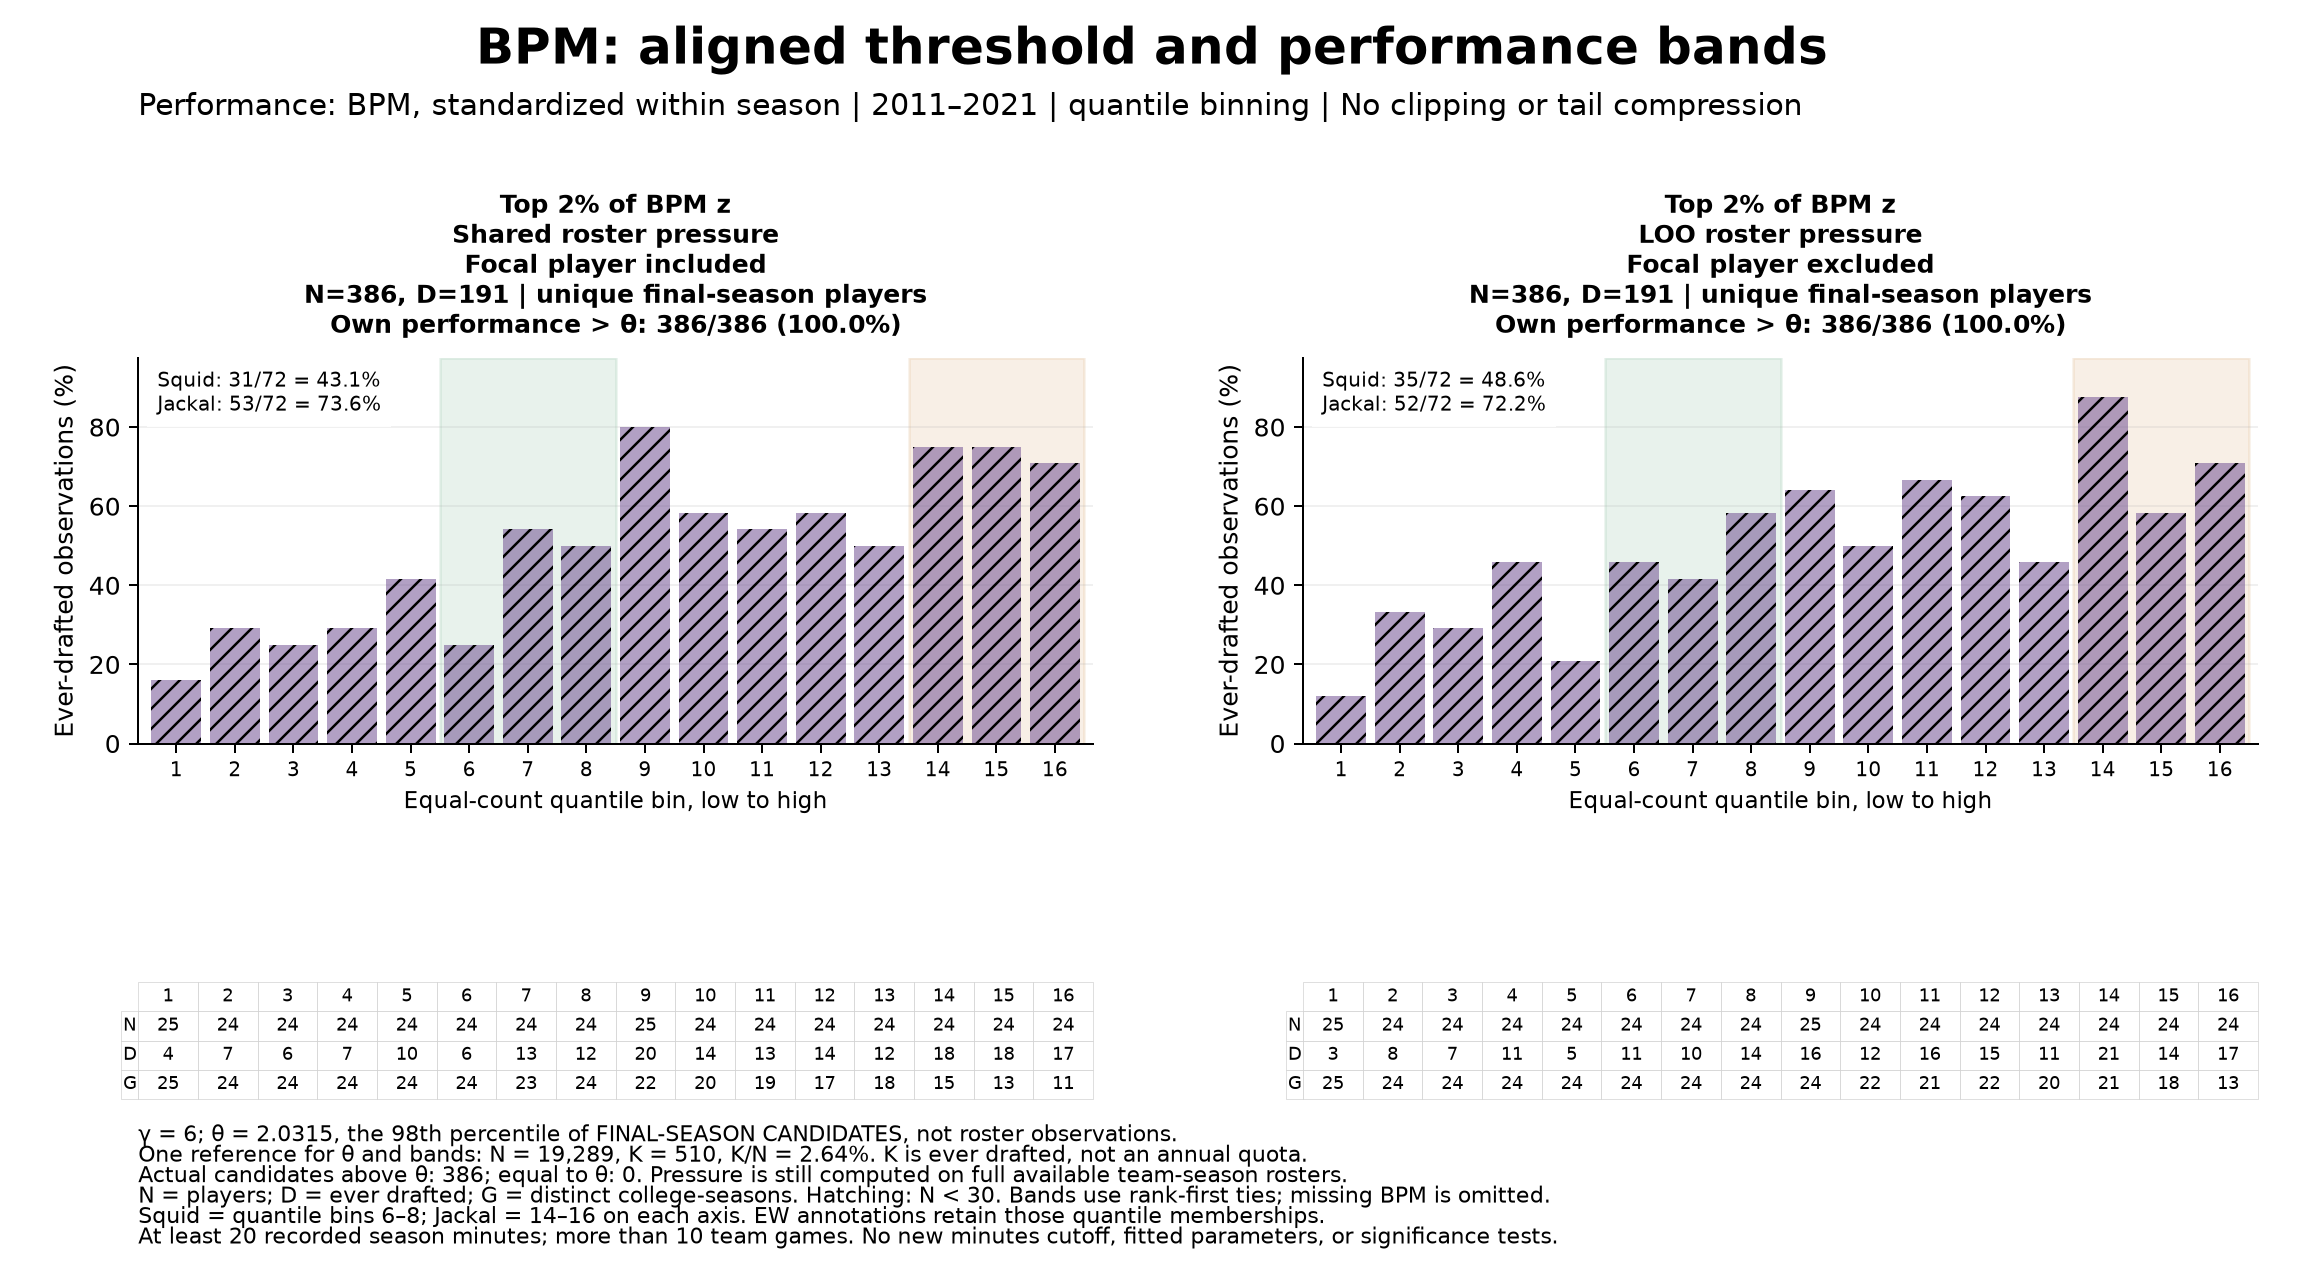

In [4]:
show_run_settings()
display(Image(filename=str(RUN / 'aligned_BPM_HERO_top_quantile.png')))

### Middle band

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

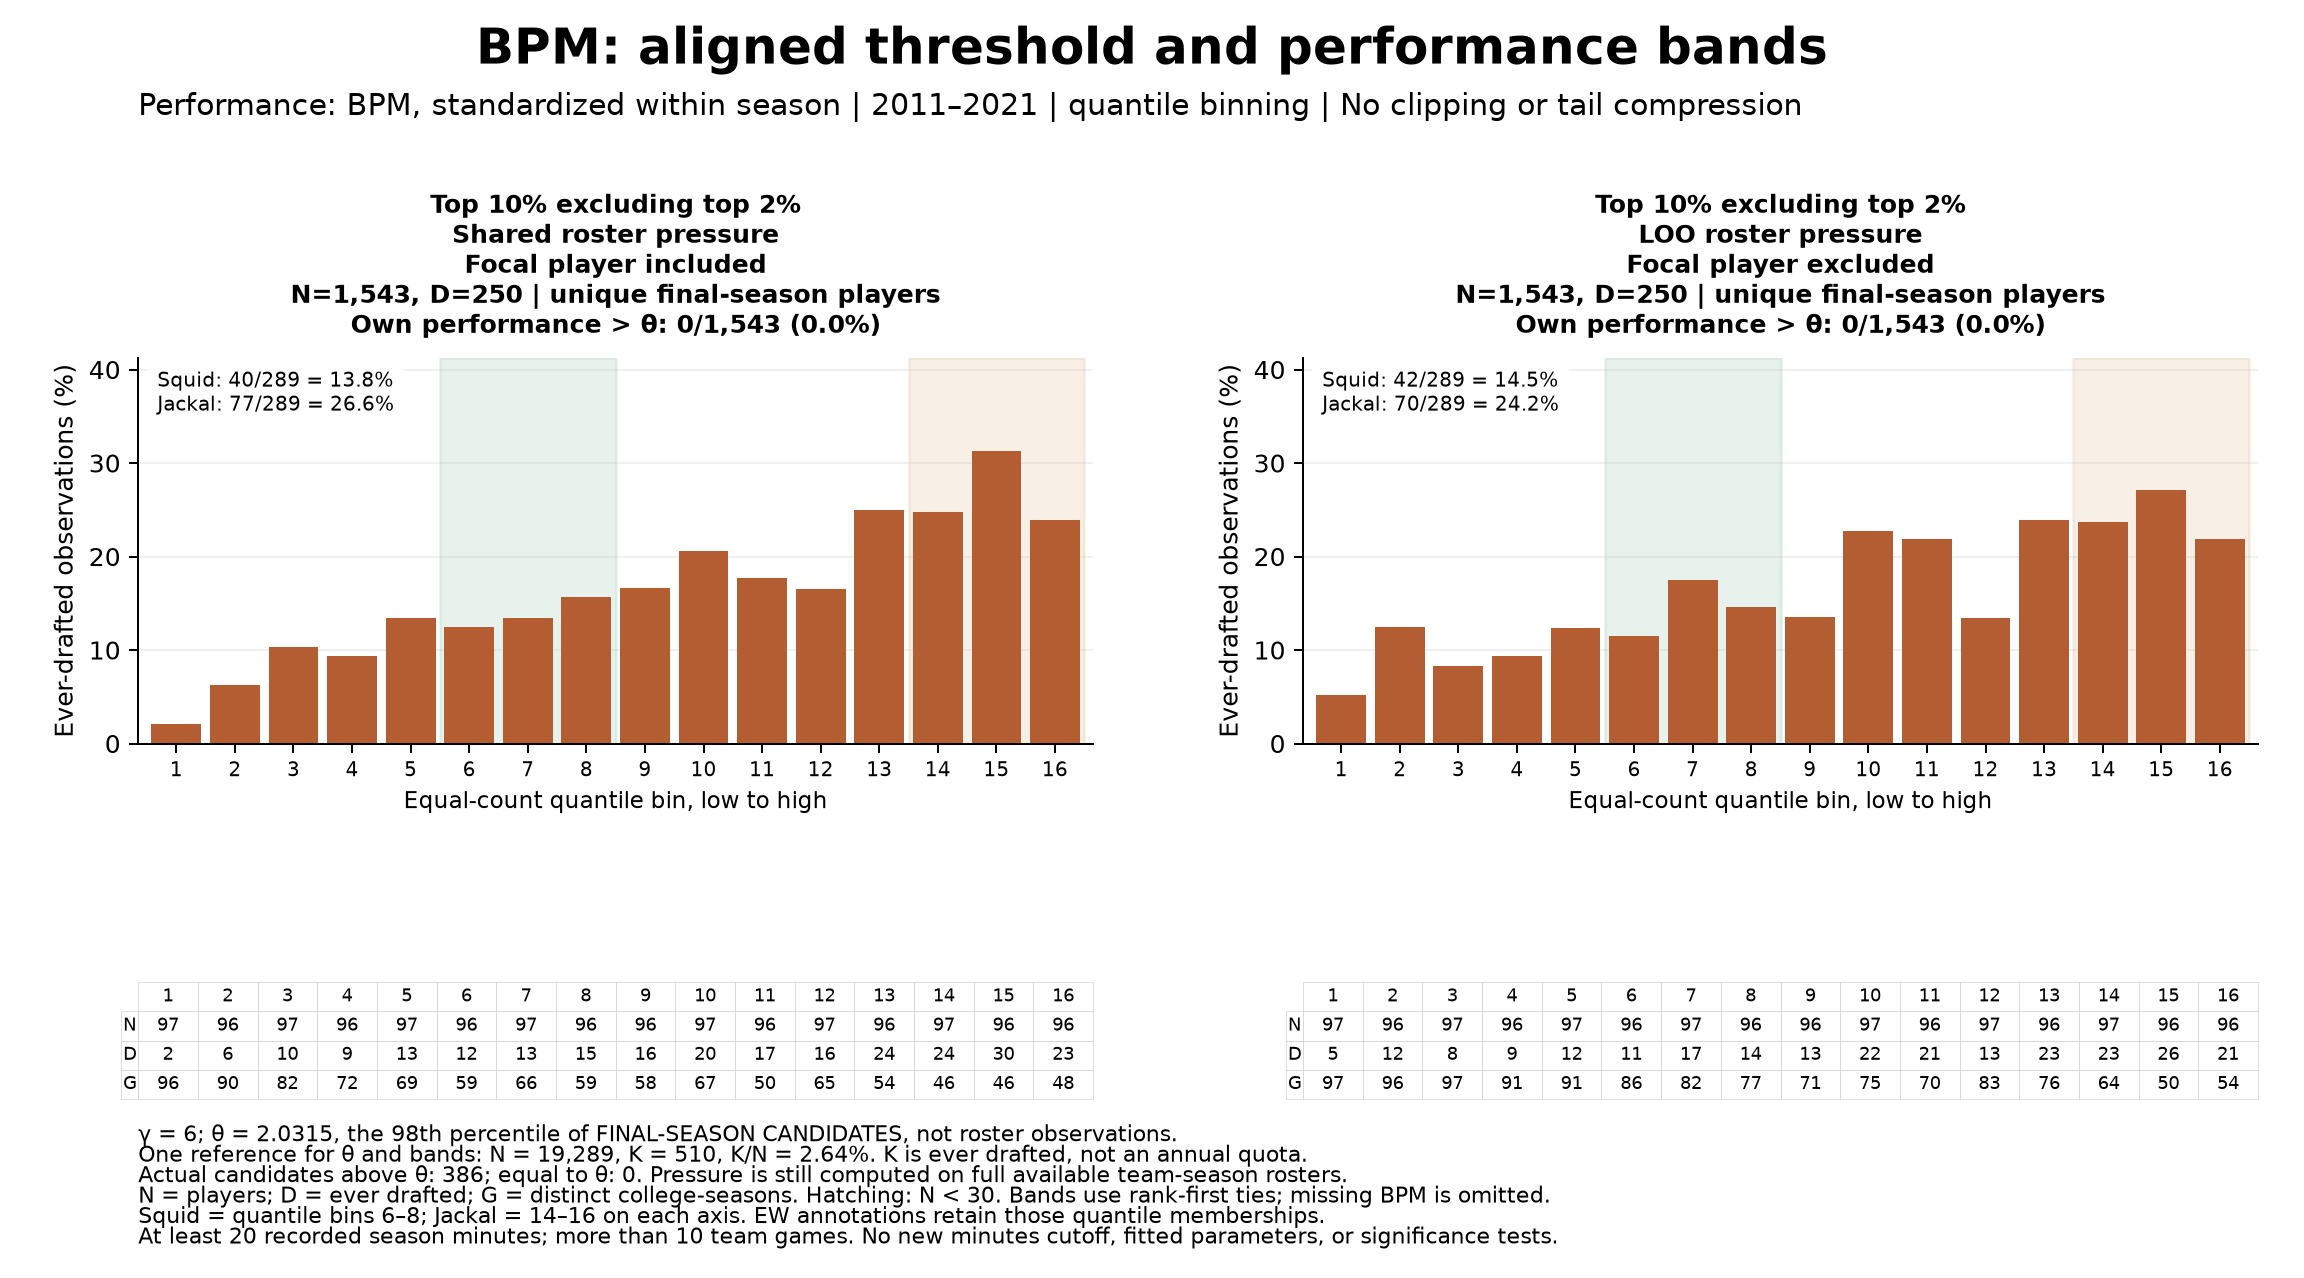

In [5]:
show_run_settings()
display(Image(filename=str(RUN / 'aligned_BPM_HERO_middle_quantile.png')))

### Lower band

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

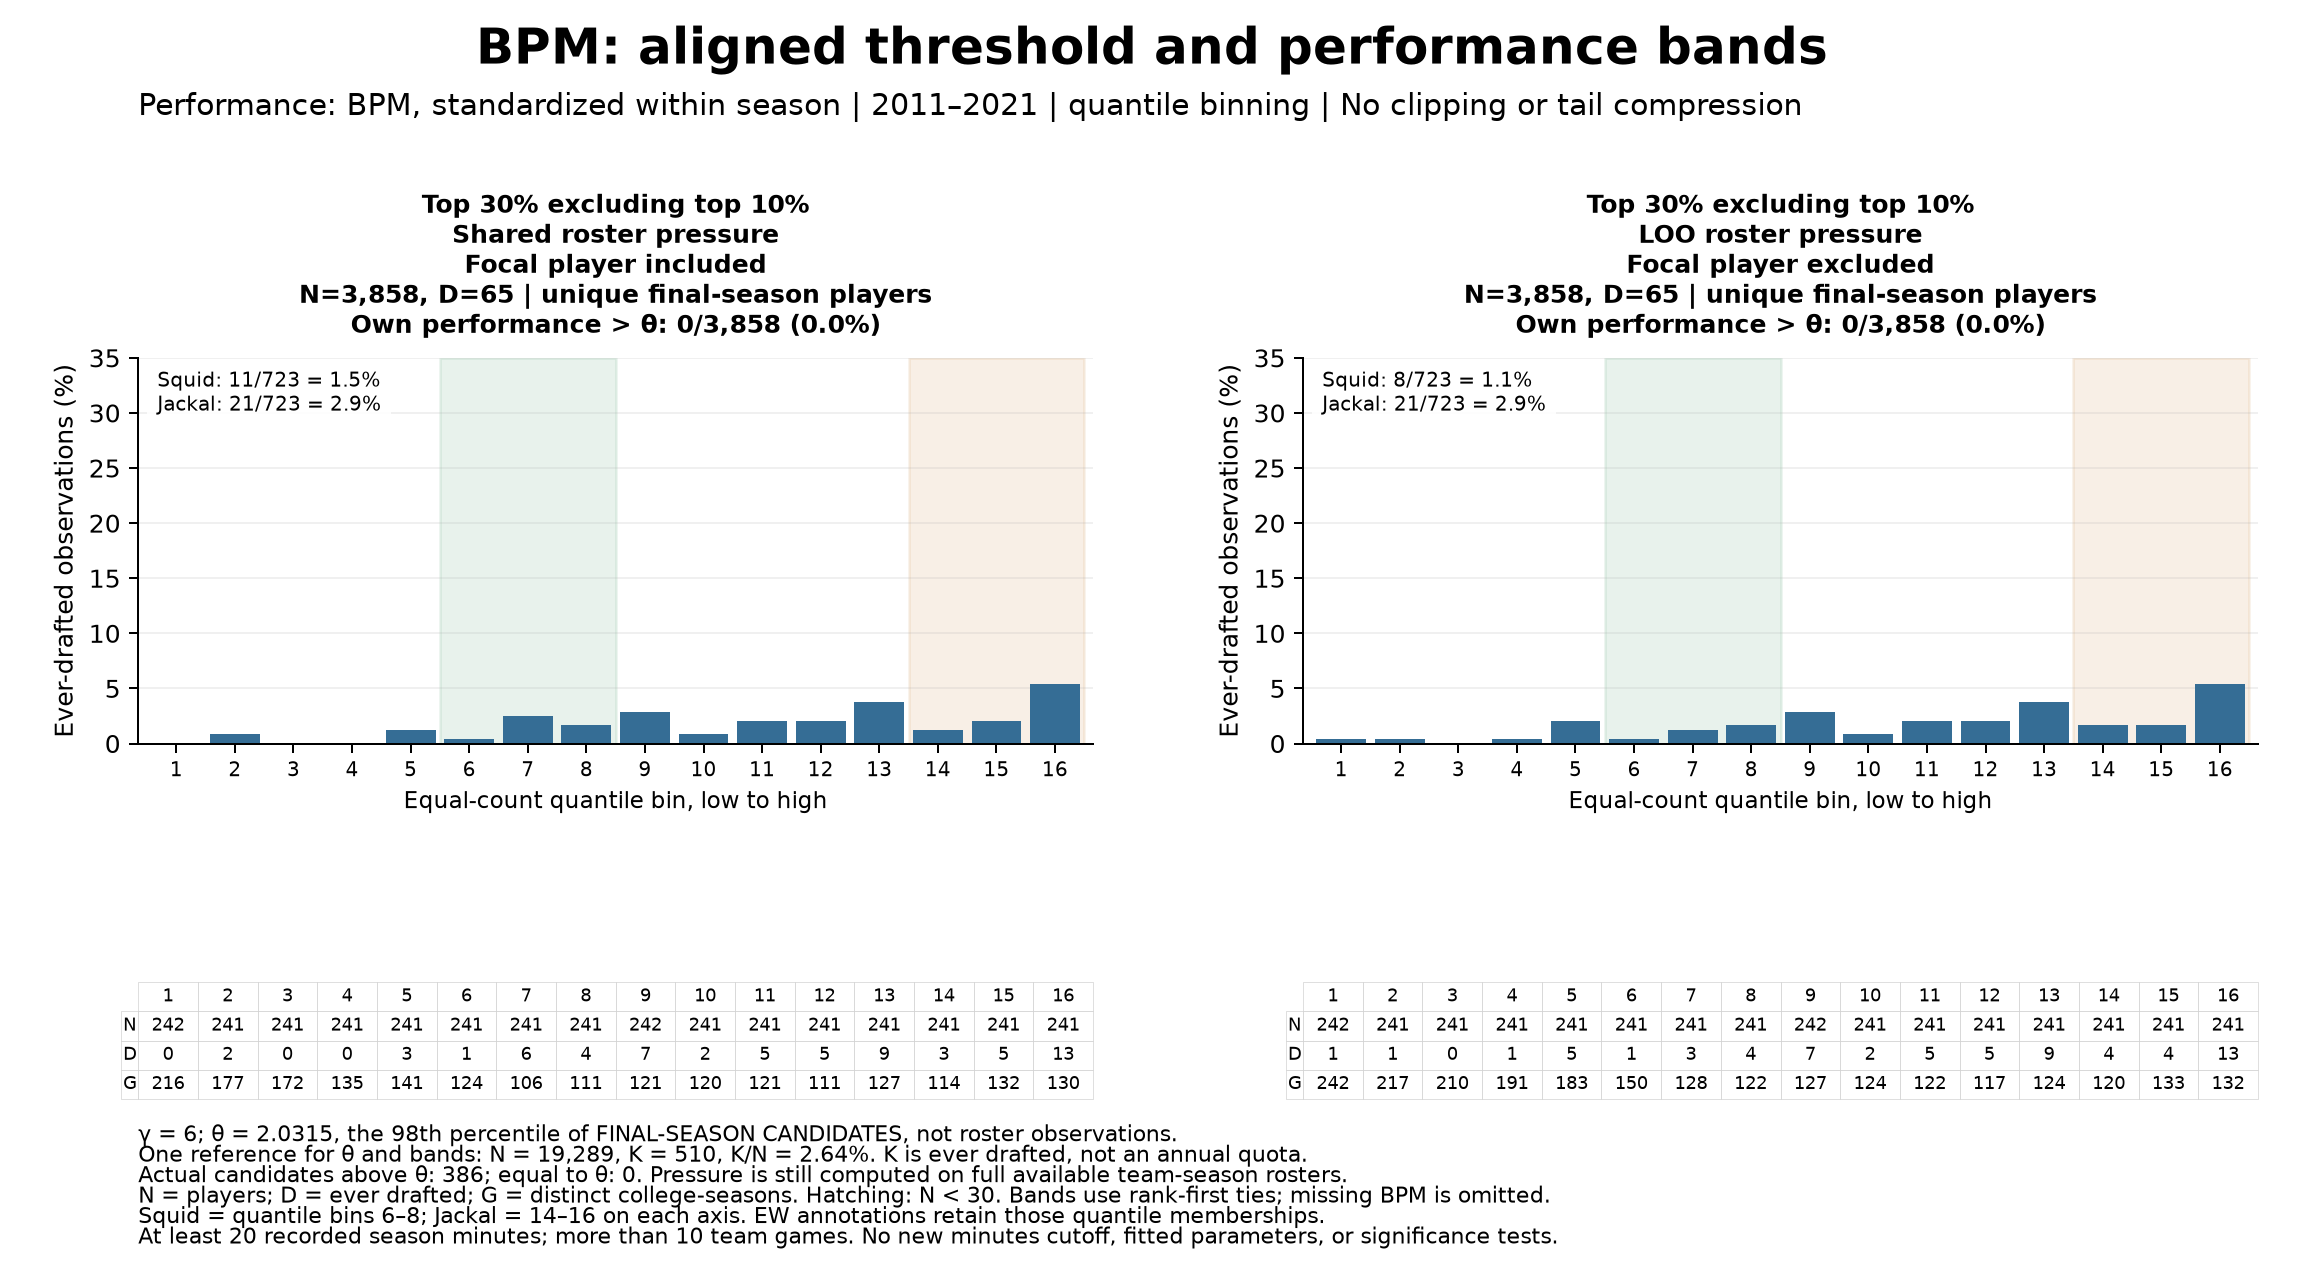

In [6]:
show_run_settings()
display(Image(filename=str(RUN / 'aligned_BPM_HERO_lower_quantile.png')))

## 5 Equal-width comparisons

EW edges are common across bands and shared/LOO pressure. There is no clipping or compressed tail. Empty bins remain empty. Squid/Jackal annotations retain quantile-defined membership and therefore do not mean EW bins 6–8 and 14–16.

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

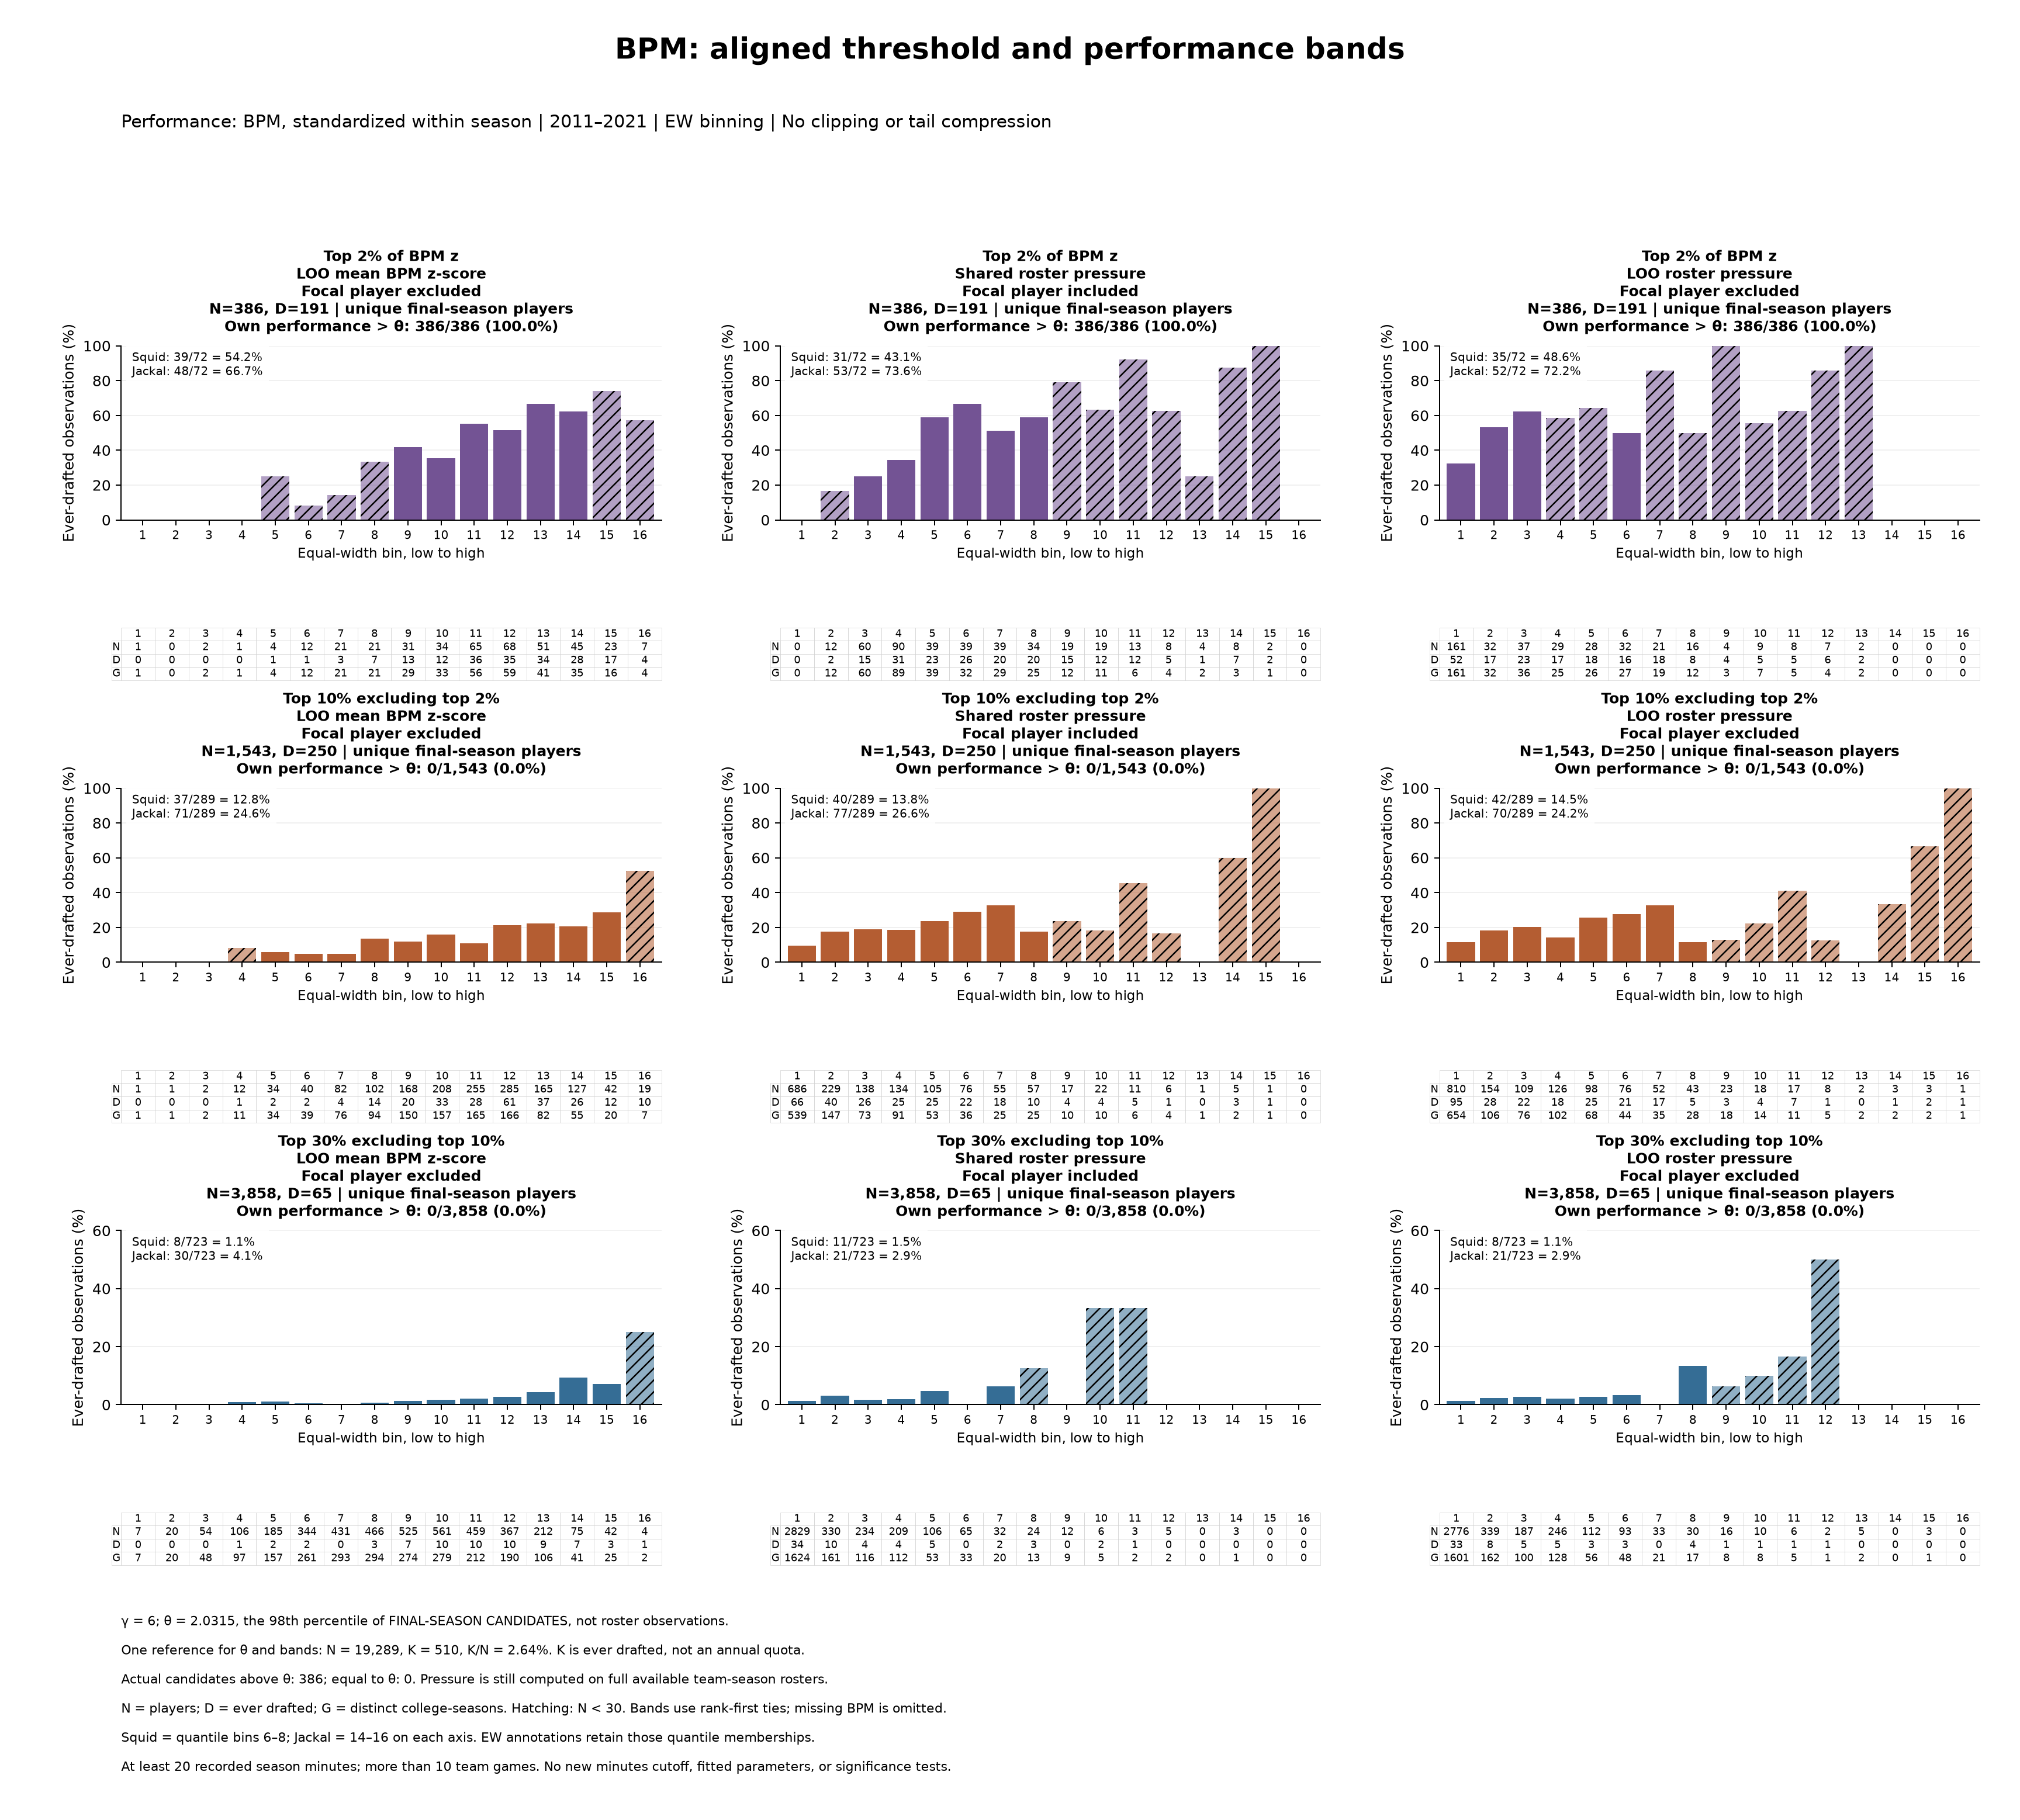

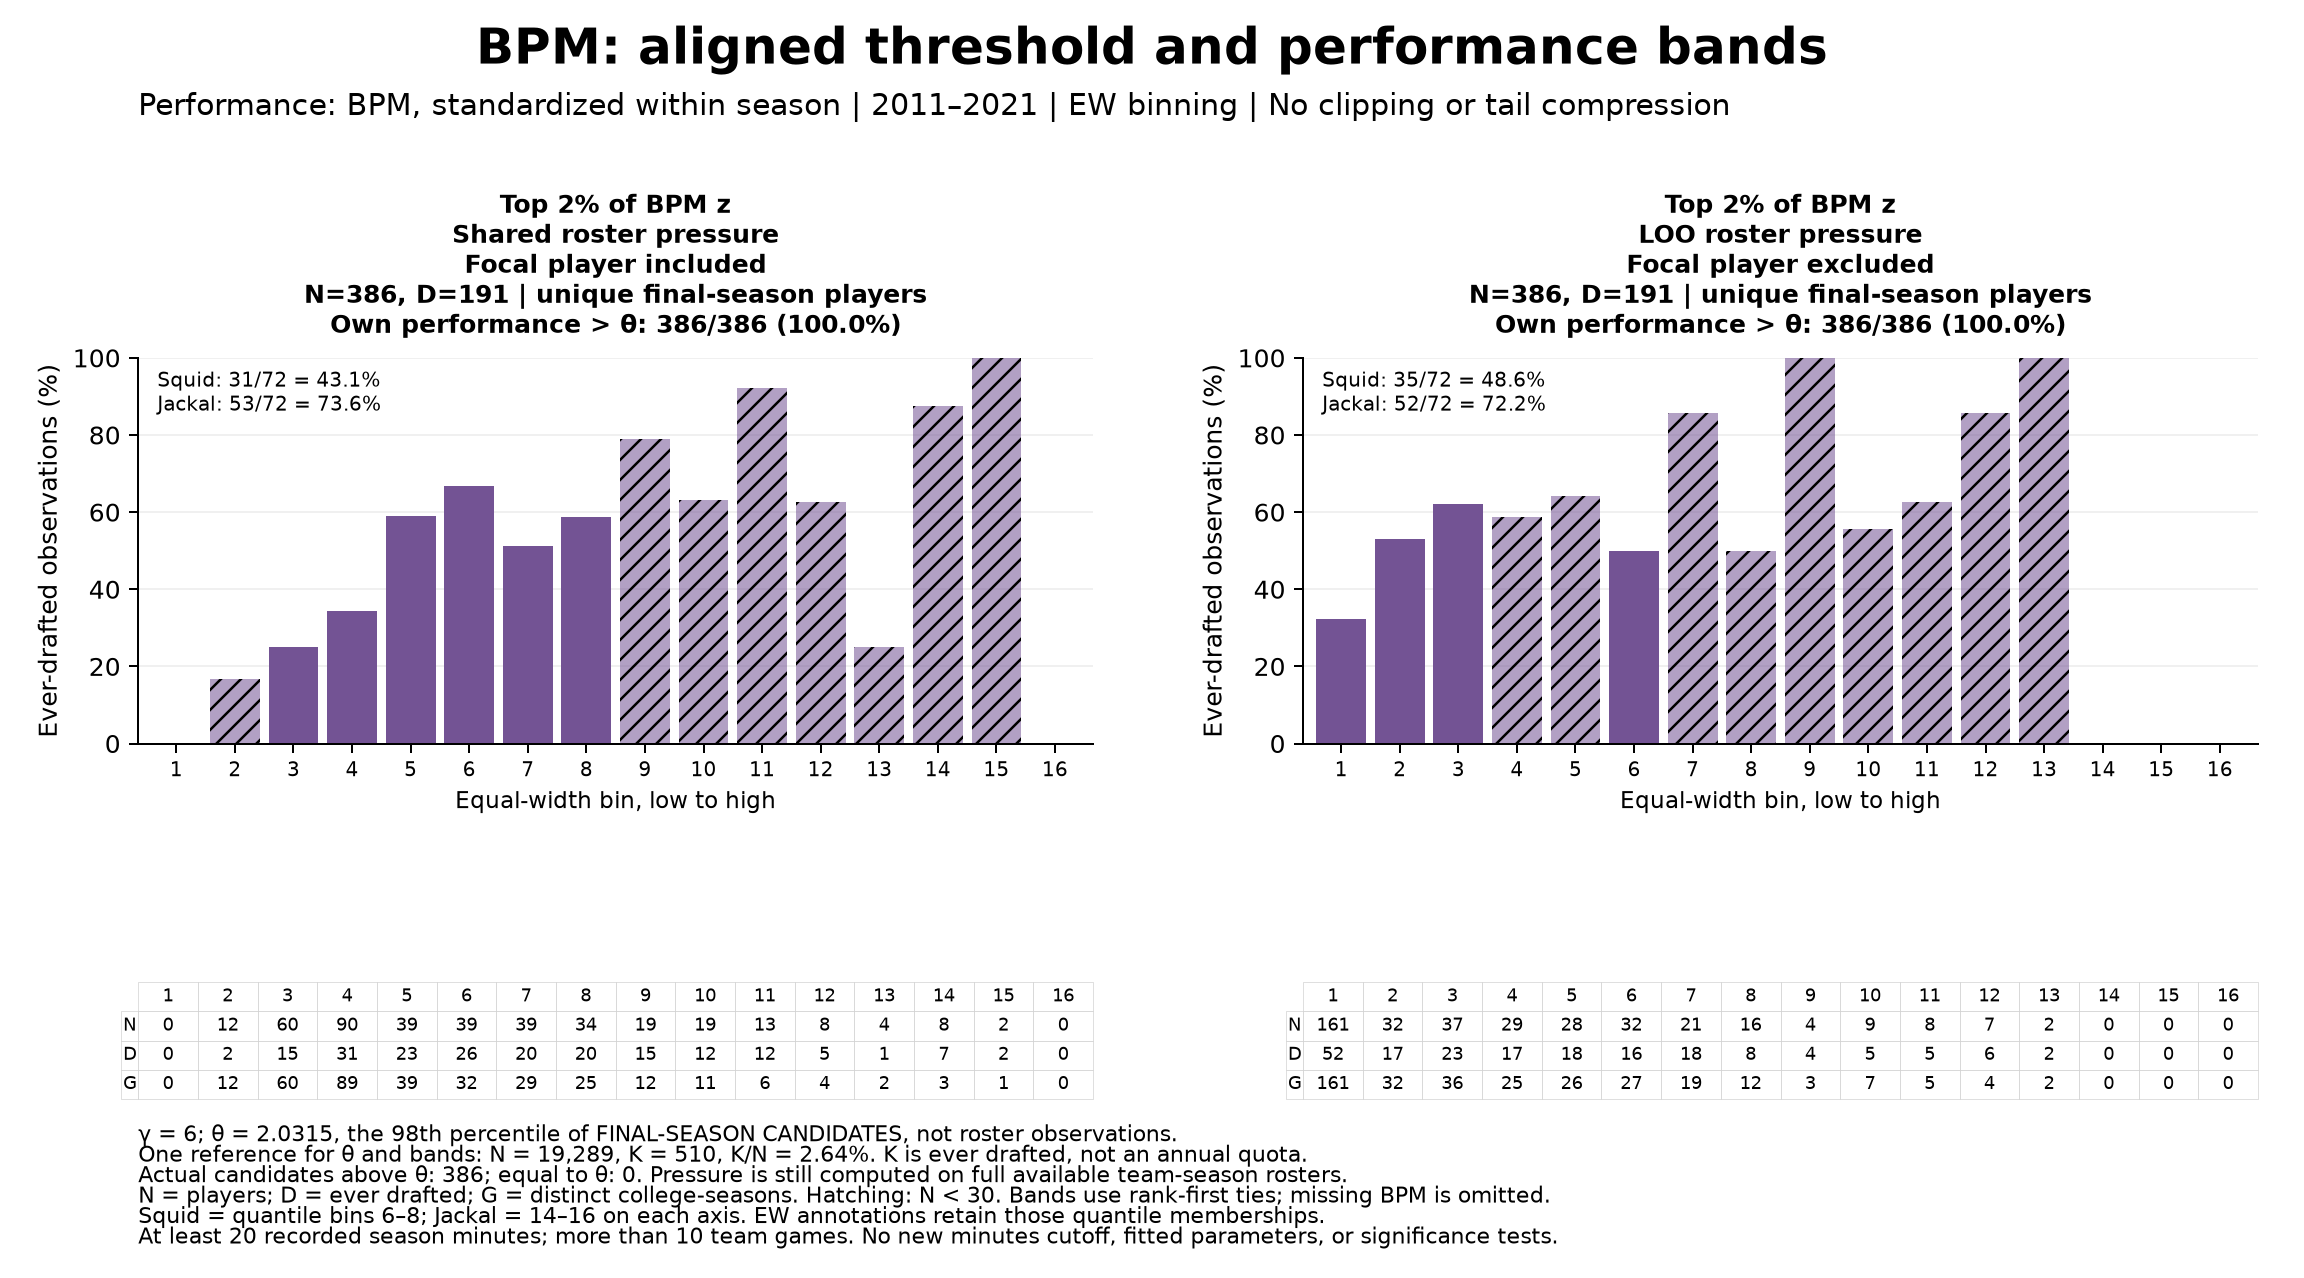

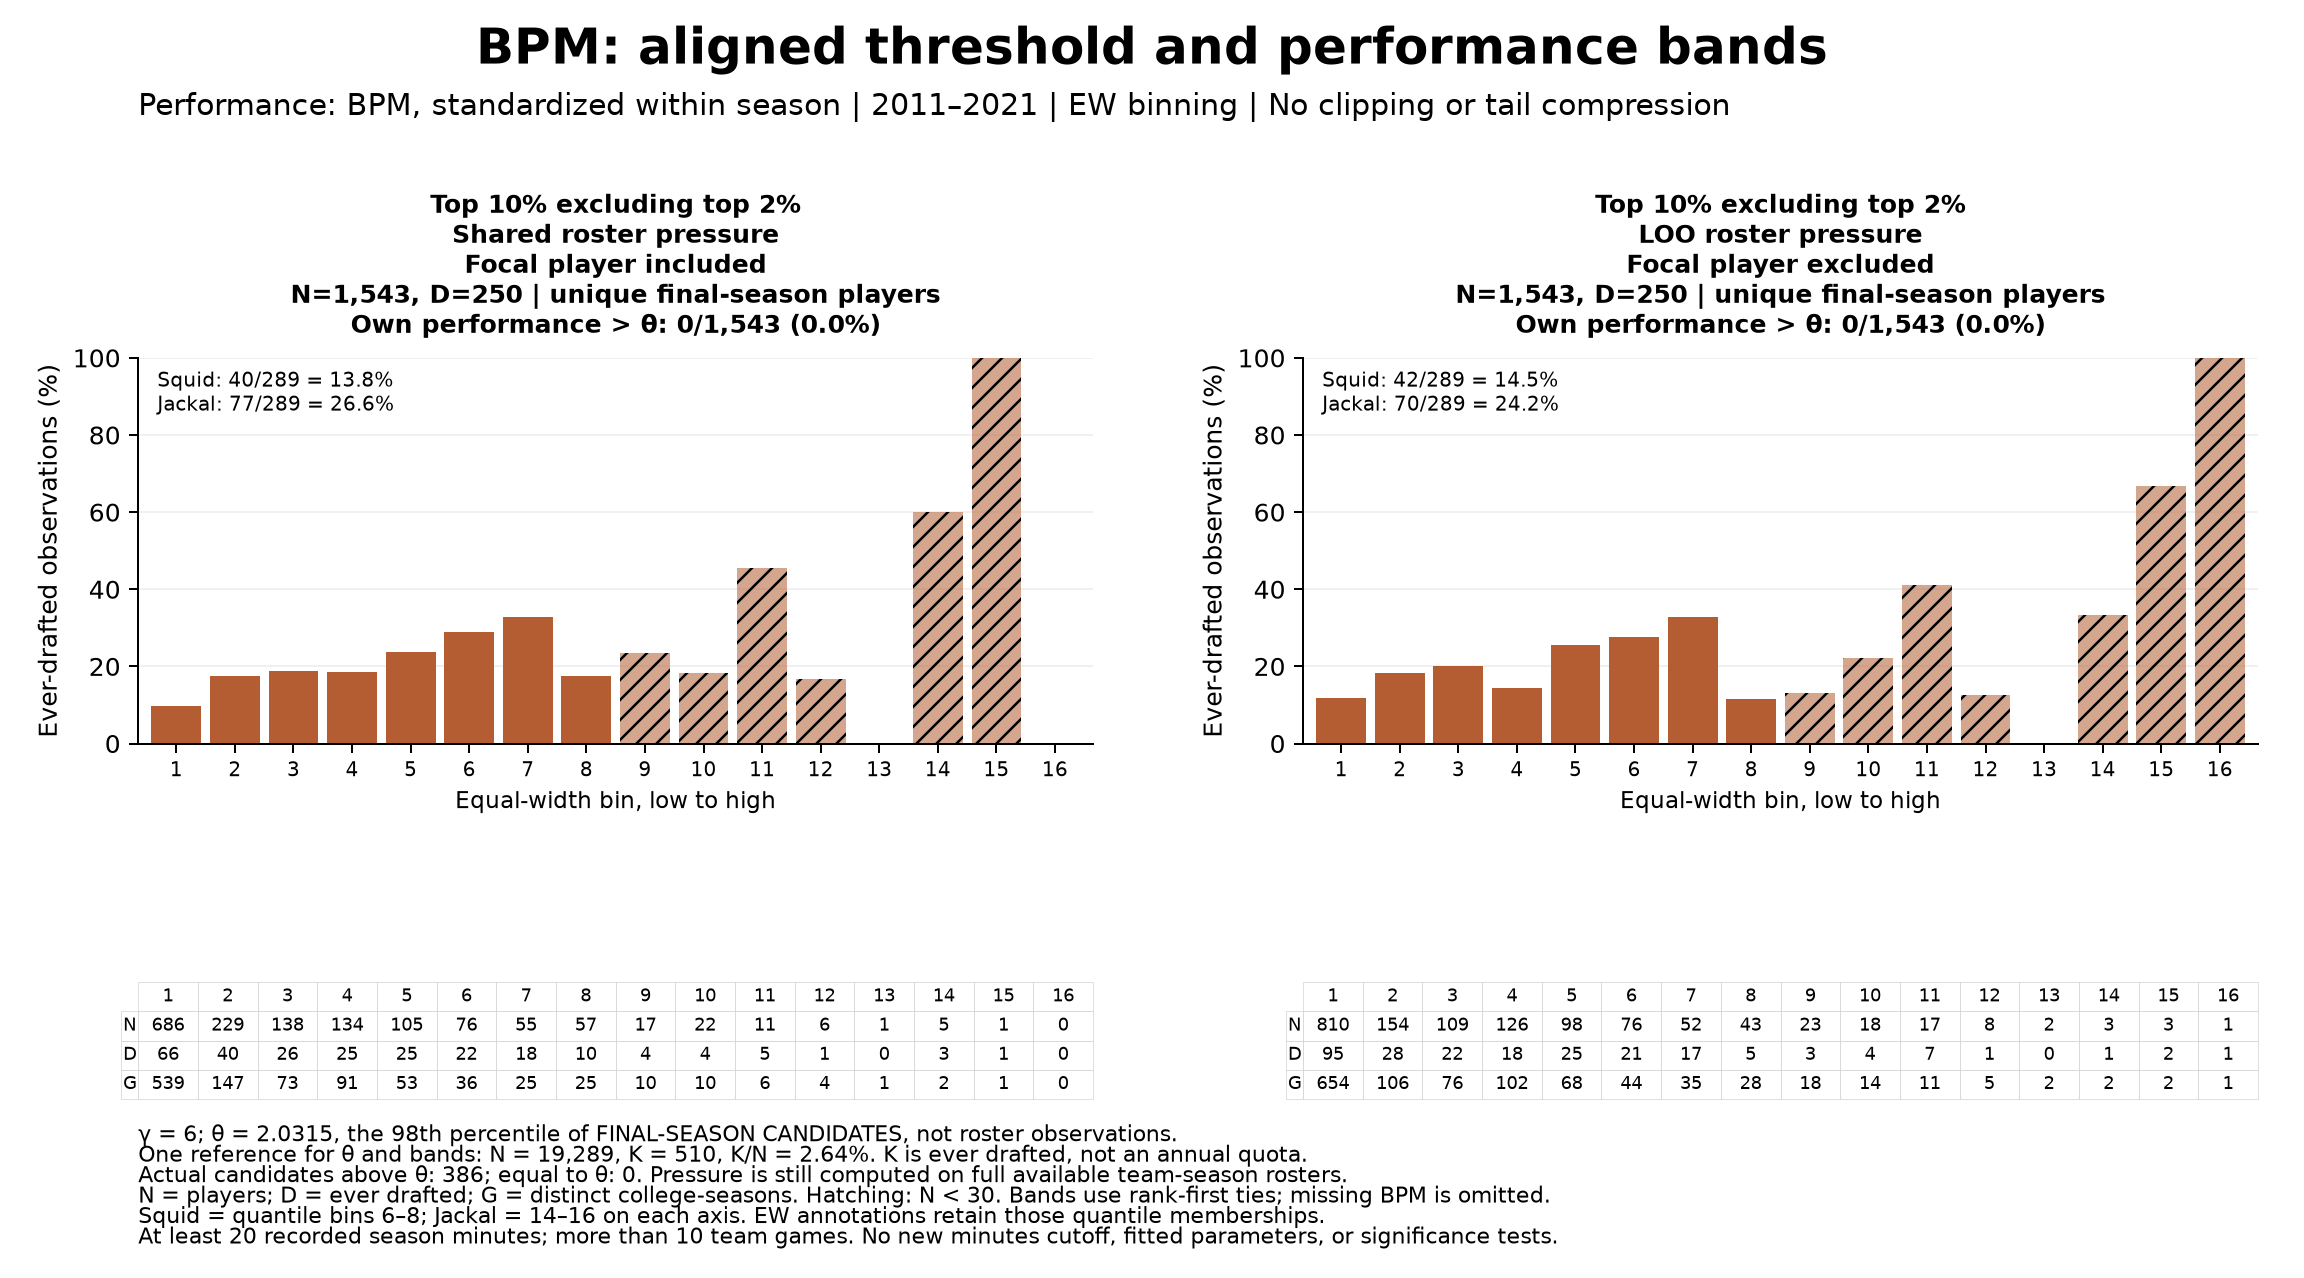

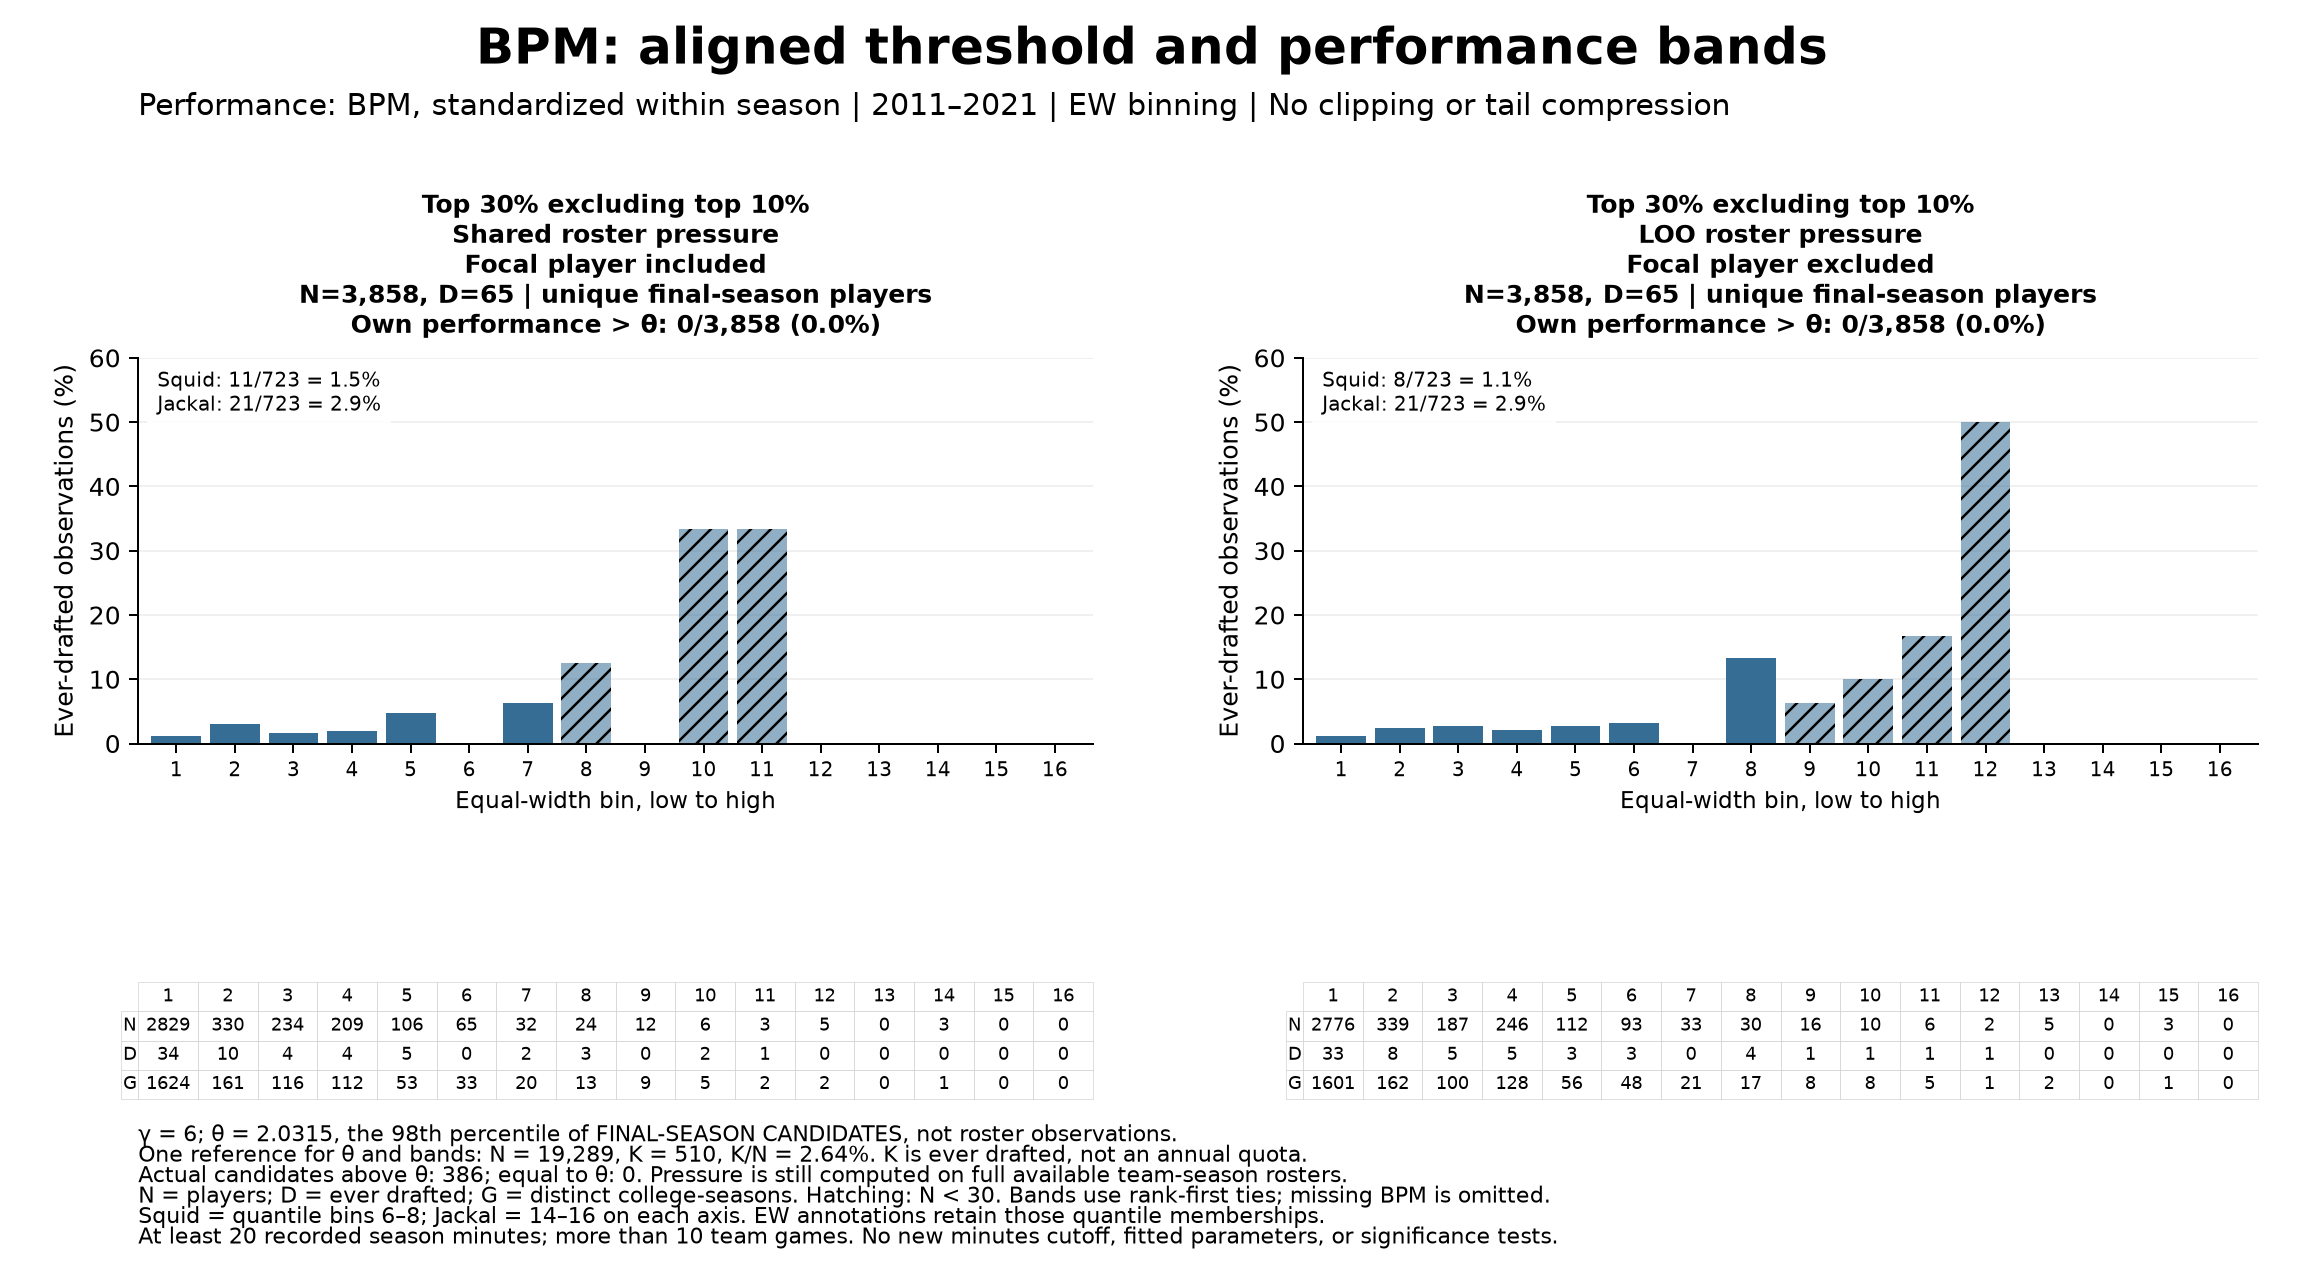

In [7]:
show_run_settings()
display(Image(filename=str(RUN / 'aligned_BPM_mosaic_EW.png')))
for name in ['top','middle','lower']:
    display(Image(filename=str(RUN / f'aligned_BPM_HERO_{name}_EW.png')))

## 6 Counts and the journal trail

At the initial settings, the top band is 386 players with 191 ever drafted (49.5%); the middle is 1,543 with 250 (16.2%); the lower is 3,858 with 65 (1.7%). These are a dated baseline observation, not live results if settings change. Use the tables above and below for the active run.

The high-pressure Jackal region exceeds the middle Squid region for both pressure definitions in all three bands at the initial settings. This does not establish a causal benefit of congestion. Nor does it rule out a downturn within a narrower ability range. The top band still includes 75 players with fewer than 100 recorded season minutes. We have not solved that eligibility concern by changing the performance metric.

The previous top 2% used raw BPM ranks and roster-based theta (1.9015). This experiment uses standardized BPM ranks and candidate-based theta (2.0315). Of 386 old top-band members, 363 remain and 23 are replaced. The new wider middle and lower bands are another change. No difference between runs should be attributed to a single cause.

In [8]:
show_run_settings()
display(pd.read_csv(RUN / 'band_boundary_ties.csv'))
display(pd.read_csv(RUN / 'baseline_top2_membership_overlap.csv'))
r = pd.read_csv(RUN / 'squid_jackal_counts.csv')
display(r.loc[r.method.eq('quantile'), ['cohort','axis','group','n','positive_rows','rate','team_seasons']])
print('Printable plots:', RUN / 'Aligned_BPM_printable_comparisons.pdf')
print('Exact settings and source hashes:', RUN / 'provenance.json')

**Run 20261025_191833_184458** | BPM standardized within season | theta percentile 98 | gamma 6 | bands top 2%, then to top 10%, then to top 30%

,top_fraction,rank,performance,tied_observations,tied_at_or_above_rank,tied_below_rank
0,0.02,386,2.033313,3,3,0
1,0.10,1929,1.284989,10,6,4
2,0.30,5787,0.518697,13,9,4


,band_rank,lower,middle,outside,top
0,baseline_other,3858,1520,13502,23
1,baseline_top2,0,23,0,363


,cohort,axis,group,n,positive_rows,rate,team_seasons
0,top,loo_performance,Squid,72,39,0.541667,63
1,top,loo_performance,Jackal,72,48,0.666667,48
2,top,rp_shared,Squid,72,31,0.430556,71
3,top,rp_shared,Jackal,72,53,0.736111,39
4,top,rp_loo,Squid,72,35,0.486111,72
5,top,rp_loo,Jackal,72,52,0.722222,42
6,middle,loo_performance,Squid,289,37,0.128028,204
7,middle,loo_performance,Jackal,289,71,0.245675,125
8,middle,rp_shared,Squid,289,40,0.138408,183
9,middle,rp_shared,Jackal,289,77,0.266436,138


Printable plots: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison/aligned_threshold_bands/runs/20261025_191833_184458/Aligned_BPM_printable_comparisons.pdf
Exact settings and source hashes: /Users/charleslevine/Library/CloudStorage/Dropbox/1-Documents/00- Dissertation/0-Next_Chapter/Code_and_Data/New SQL and PY Code/Cursor Workspace PDE/3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/roster_pressure_comparison/aligned_threshold_bands/runs/20261025_191833_184458/provenance.json


## 7 Return to the previous branch

Open `../NCAA_Shared_vs_LOO_Roster_Pressure_BPM.ipynb` for the prior raw-BPM top/next-band experiment. Its saved run is `../bpm_runs/20261025_184918_282428`. The PPM notebook is also untouched. A snapshot of the BPM notebook, module and run pointer is in this experiment's `baseline` folder. `experiment_plan.json` records the decision before plotting. Every aligned run saves settings, counts, memberships and source/code hashes in its own `runs` subfolder.

The printable explanation is Entry 7 in `NCAA_Evidence_Walkthrough.docx`, under `3-Master_Plan/re_entry/NCAA_Guided_Walkthrough`. Next, read the top-band pair together before choosing another experiment. No 2.5% run, minutes filter, or significance test is implied by this notebook.